# Climate change vs forest expansion: land temperature (2001–2040)

**Question (user 2026-11-25).** The paper compares the effect of the forest expansion with that of the 2000 → 2100 climate change. At the top of the atmosphere (TOA) the forest is ~1/5 of the climate signal, for the surface-albedo proxy ~1/14 (`pd-fut-attribution`). Both are radiation measures, and they are not equally fair: with prescribed SST and sea ice, the **climate contrast already contains the ocean and sea-ice response** (the 2100 SSTs are imposed), the **forest contrast only the fast response** (same SSTs in LCC and CTRL). Land temperature responds in **both** contrasts (the land surface is free in both), so it is the closest like-for-like measure we have.

**Contrasts** (interactive runs, paired years 2001–2040):
- climate: `CTRL_[FUT − PD]` = CTRL_FUT − CTRL_PD
- forest, FUT background: `[LCC − CTRL]_FUT`; forest, PD background: `[LCC − CTRL]_PD`

**Fields** (CLM, land only, processed `lnd LAND` files): `TSA` = 2 m air temperature over land, `TSKIN` = skin (radiative surface) temperature. Annual and seasonal (DJF = Jan, Feb, Dec of the same year).

**Regions:** modified cells (land), unmodified land ≥45°N, all land ≥45°N; weights = cell area × land fraction (`forcing_maps.region_weights`). Mean ± 95 % t-interval of the yearly regional means (n = 40). Maps: cell-wise t-test + FDR (α = 0.10, ≥45°N); hatched = not significant.

**Caveat (also in the draft Methods):** even for temperature the comparison is not symmetric. Over land near the ocean, the prescribed 2100 SSTs and sea ice warm the air directly in the climate contrast; the forest cannot warm the ocean, and nudging to PD winds limits how far its effect spreads. So the forest/climate ratio is a lower bound of the full (coupled) ratio.

Outputs: `results/figures/climate-vs-lcc-land-temperature/`, `results/tables/climate-vs-lcc-land-temperature/`.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from scipy import stats
from IPython.display import display

REPO = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))
from boreal_forest_expansion.plotting import forcing_maps as fm  # noqa: E402
from boreal_forest_expansion.analysis.stats import cellwise_pvalue, fdr_mask  # noqa: E402
from boreal_forest_expansion.plotting.style import set_default_style  # noqa: E402

set_default_style()
STEM = "climate-vs-lcc-land-temperature"
FIG, TAB = fm.set_output_notebook(STEM)
START_YEAR, END_YEAR = 2001, 2040
LAT_MIN, FDR_ALPHA = 45.0, 0.10

CONTRASTS = {"CTRL_[FUT − PD]": ("CTRL_FUT", "CTRL_PD"),
             "[LCC − CTRL]_FUT": ("LCC_FUT", "CTRL_FUT"),
             "[LCC − CTRL]_PD": ("LCC_PD", "CTRL_PD")}
CLIMATE, FOREST = "CTRL_[FUT − PD]", "[LCC − CTRL]_FUT"
VARS = {"TSA": "2 m air temperature", "TSKIN": "skin temperature"}
SEASONS = {"ANN": None, "DJF": fm.SEASONS["DJF"], "MAM": fm.SEASONS["MAM"],
           "JJA": fm.SEASONS["JJA"], "SON": fm.SEASONS["SON"]}
NAVY, RED, GOLD = "#2C3990", "#BC423E", "#EBC45C"   # project palette: climate (FUT − PD) navy, forest (LCC) red
print("outputs:", FIG, TAB)

outputs: /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/climate-vs-lcc-land-temperature /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/tables/climate-vs-lcc-land-temperature


In [2]:
# Yearly (and seasonal) means of every run; a few retries for NIRD read errors (HDF error, Errno 5)
def yearly_means(alias):
    for attempt in range(1, 6):
        try:
            ds = fm.open_class(alias, "LAND", START_YEAR, END_YEAR, component="lnd")
            out = {(v, s): fm.annual_mean(ds[v], ds, m).load() for v in VARS for s, m in SEASONS.items()}
            static = ds[["area", "landfrac"]].load()
            ds.close()
            return out, static
        except (RuntimeError, OSError) as exc:
            print(f"{alias}: read failed, attempt {attempt}/5: {exc}", flush=True)
            time.sleep(30 * attempt)
    raise RuntimeError(f"{alias}: could not read")

RUNS = sorted({a for pair in CONTRASTS.values() for a in pair})
Y, STATIC = {}, None
for a in RUNS:
    Y[a], st = yearly_means(a)
    if STATIC is None:
        STATIC = st
    else:   # same land grid in every run (checked, not assumed)
        assert np.allclose(STATIC["landfrac"].fillna(0), st["landfrac"].fillna(0)), a
    print(a, "years", int(Y[a]["TSA", "ANN"]["year"][0]), "–", int(Y[a]["TSA", "ANN"]["year"][-1]))

D = {(c, v, s): Y[a][v, s] - Y[b][v, s] for c, (a, b) in CONTRASTS.items() for v in VARS for s in SEASONS}
assert all(d.sizes["year"] == END_YEAR - START_YEAR + 1 for d in D.values())

CTRL_FUT years 2001 – 2040
CTRL_PD years 2001 – 2040
LCC_FUT years 2001 – 2040
LCC_PD years 2001 – 2040


In [3]:
# Regional means: area x land fraction, mean ± 95 % t-interval of the yearly regional means
MASKS = fm.region_masks(STATIC, lat_min=LAT_MIN)
W = fm.region_weights(STATIC)
land_north = MASKS[f"≥{LAT_MIN:g}°N"] & (STATIC["landfrac"].fillna(0) > 0)
REGIONS = {"modified cells": MASKS["modified cells"],
           f"unmodified land ≥{LAT_MIN:g}°N": MASKS[f"unmodified land ≥{LAT_MIN:g}°N"],
           f"land ≥{LAT_MIN:g}°N": land_north}
for name, m in REGIONS.items():
    print(f"{name}: {int(m.sum())} cells, {float((fm.cell_area(STATIC) * STATIC['landfrac'].fillna(0)).where(m).sum()) / 1e12:.1f} Mkm² land")


def interval(series):
    r = np.asarray(series)
    return r.mean(), stats.t.ppf(0.975, r.size - 1) * r.std(ddof=1) / np.sqrt(r.size)


rows = []
for (c, v, s), d in D.items():
    for rname, m in REGIONS.items():
        mean, half = interval(d.weighted(W.where(m, 0.0)).mean(("lat", "lon")).values)
        rows.append(dict(variable=v, season=s, region=rname, contrast=c, mean=mean, ci95=half, n=d.sizes["year"]))
T = pd.DataFrame(rows)
T.to_csv(TAB / f"land_temperature_{START_YEAR}_{END_YEAR}.csv", index=False)

# forest / climate ratio (FUT background), with the yearly pairing kept: ratio of the means
piv = T.pivot_table(index=["variable", "region", "season"], columns="contrast", values="mean", sort=False)
ci = T.pivot_table(index=["variable", "region", "season"], columns="contrast", values="ci95", sort=False)
R = pd.DataFrame({"climate (K)": piv[CLIMATE].map("{:+.2f}".format) + " ± " + ci[CLIMATE].map("{:.2f}".format),
                  "forest FUT (K)": piv[FOREST].map("{:+.3f}".format) + " ± " + ci[FOREST].map("{:.3f}".format),
                  "forest PD (K)": piv["[LCC − CTRL]_PD"].map("{:+.3f}".format) + " ± " + ci["[LCC − CTRL]_PD"].map("{:.3f}".format),
                  "forest FUT / climate (%)": (100 * piv[FOREST] / piv[CLIMATE]).round(1)})
pd.set_option("display.width", 220, "display.max_rows", 200)
display(R)

modified cells: 1152 cells, 24.4 Mkm² land
unmodified land ≥45°N: 670 cells, 15.6 Mkm² land
land ≥45°N: 1822 cells, 40.1 Mkm² land


climate (K)  forest FUT (K)   forest PD (K)  forest FUT / climate (%)
variable region                season                                                                        
TSA      modified cells        ANN     +7.42 ± 0.04  +0.110 ± 0.004  +0.130 ± 0.004                       1.5
                               DJF     +9.60 ± 0.10  +0.038 ± 0.005  +0.029 ± 0.006                       0.4
                               MAM     +6.03 ± 0.05  +0.204 ± 0.008  +0.275 ± 0.007                       3.4
                               JJA     +7.15 ± 0.07  +0.131 ± 0.008  +0.168 ± 0.010                       1.8
                               SON     +6.95 ± 0.06  +0.066 ± 0.004  +0.046 ± 0.005                       0.9
         unmodified land ≥45°N ANN     +5.34 ± 0.03  +0.005 ± 0.003  +0.005 ± 0.004                       0.1
                               DJF     +5.06 ± 0.06  -0.000 ± 0.003  -0.013 ± 0.005                      -0.0
                               MAM     +4.57 ± 0.06  -0.015 ± 0.006  -0.019 ± 0.008                      -0.3
                               JJA     +6.46 ± 0.05  +0.022 ± 0.007  +0.046 ± 0.008                       0.3
                               SON     +5.26 ± 0.03  +0.013 ± 0.004  +0.006 ± 0.005                       0.3
         land ≥45°N            ANN     +6.61 ± 0.03  +0.069 ± 0.003  +0.081 ± 0.003                       1.0
                               DJF     +7.83 ± 0.08  +0.023 ± 0.003  +0.013 ± 0.004                       0.3
                               MAM     +5.46 ± 0.05  +0.118 ± 0.006  +0.160 ± 0.006                       2.2
                               JJA     +6.88 ± 0.06  +0.089 ± 0.008  +0.120 ± 0.008                       1.3
                               SON     +6.29 ± 0.04  +0.045 ± 0.004  +0.031 ± 0.004                       0.7
TSKIN    modified cells        ANN     +7.55 ± 0.04  +0.155 ± 0.004  +0.166 ± 0.004                       2.1
                               DJF     +9.77 ± 0.10  +0.054 ± 0.005  +0.049 ± 0.006                       0.6
                               MAM     +6.17 ± 0.05  +0.236 ± 0.009  +0.311 ± 0.007                       3.8
                               JJA     +7.29 ± 0.07  +0.234 ± 0.009  +0.231 ± 0.011                       3.2
                               SON     +7.02 ± 0.06  +0.095 ± 0.004  +0.067 ± 0.005                       1.3
         unmodified land ≥45°N ANN     +5.52 ± 0.03  +0.005 ± 0.003  +0.006 ± 0.005                       0.1
                               DJF     +5.25 ± 0.06  +0.000 ± 0.003  -0.012 ± 0.005                       0.0
                               MAM     +4.74 ± 0.07  -0.015 ± 0.007  -0.018 ± 0.009                      -0.3
                               JJA     +6.67 ± 0.05  +0.022 ± 0.008  +0.047 ± 0.009                       0.3
                               SON     +5.43 ± 0.03  +0.013 ± 0.004  +0.005 ± 0.005                       0.2
         land ≥45°N            ANN     +6.76 ± 0.03  +0.097 ± 0.003  +0.103 ± 0.004                       1.4
                               DJF     +8.00 ± 0.08  +0.033 ± 0.003  +0.026 ± 0.005                       0.4
                               MAM     +5.61 ± 0.05  +0.138 ± 0.006  +0.183 ± 0.006                       2.5
                               JJA     +7.05 ± 0.06  +0.152 ± 0.008  +0.159 ± 0.009                       2.2
                               SON     +6.40 ± 0.04  +0.063 ± 0.004  +0.043 ± 0.004                       1.0

In [4]:
# One comparison table: land temperature next to the radiation measures of pd-fut-attribution (same years, same cells)
rad = pd.read_csv(REPO / f"results/tables/pd-fut-attribution/pd_fut_radiative_budget_{START_YEAR}_{END_YEAR}.csv")
rad = rad[(rad["period"] == "FUT") & rad["contrast"].isin([CLIMATE, FOREST])]
cmp_rows = []
for label, band, term in (("TOA net radiation (W m⁻²)", "NET", "toa"), ("surface-albedo proxy, SW (W m⁻²)", "SW", "albedo_proxy")):
    for rname in ("modified cells", "≥45°N"):
        sel = rad[(rad["band"] == band) & (rad["term"] == term) & (rad["region"] == rname)].set_index("contrast")
        cmp_rows.append(dict(measure=label, region=rname, season="ANN",
                             climate=sel.loc[CLIMATE, "mean"], climate_ci95=sel.loc[CLIMATE, "ci95"],
                             forest=sel.loc[FOREST, "mean"], forest_ci95=sel.loc[FOREST, "ci95"]))
for v, vname in VARS.items():
    for rname in ("modified cells", f"land ≥{LAT_MIN:g}°N"):
        for s in SEASONS:
            sel = T[(T["variable"] == v) & (T["region"] == rname) & (T["season"] == s)].set_index("contrast")
            cmp_rows.append(dict(measure=f"{vname} (K)", region=rname, season=s,
                                 climate=sel.loc[CLIMATE, "mean"], climate_ci95=sel.loc[CLIMATE, "ci95"],
                                 forest=sel.loc[FOREST, "mean"], forest_ci95=sel.loc[FOREST, "ci95"]))
C = pd.DataFrame(cmp_rows)
C["forest_over_climate_pct"] = 100 * C["forest"] / C["climate"]
C.to_csv(TAB / f"climate_vs_forest_comparison_{START_YEAR}_{END_YEAR}.csv", index=False)
display(C[C["season"].isin(["ANN", "JJA", "DJF"])].round(3))

,measure,region,season,climate,climate_ci95,forest,forest_ci95,forest_over_climate_pct
0,TOA net radiation (W m⁻²),modified cells,ANN,2.779,0.203,0.514,0.025,18.484
1,TOA net radiation (W m⁻²),≥45°N,ANN,1.100,0.117,0.217,0.016,19.739
2,"surface-albedo proxy, SW (W m⁻²)",modified cells,ANN,11.702,0.120,0.837,0.017,7.155
3,"surface-albedo proxy, SW (W m⁻²)",≥45°N,ANN,9.799,0.073,0.333,0.008,3.401
4,2 m air temperature (K),modified cells,ANN,7.424,0.039,0.110,0.004,1.485
5,2 m air temperature (K),modified cells,DJF,9.601,0.103,0.038,0.005,0.400
7,2 m air temperature (K),modified cells,JJA,7.148,0.066,0.131,0.008,1.837
9,2 m air temperature (K),land ≥45°N,ANN,6.611,0.030,0.069,0.003,1.046
10,2 m air temperature (K),land ≥45°N,DJF,7.829,0.078,0.023,0.003,0.297
12,2 m air temperature (K),land ≥45°N,JJA,6.881,0.056,0.089,0.008,1.290


findfont: Failed to find font weight semibold, now using 700.
findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/climate-vs-lcc-land-temperature/TSA_climate_vs_forest_maps_2001_2040.png


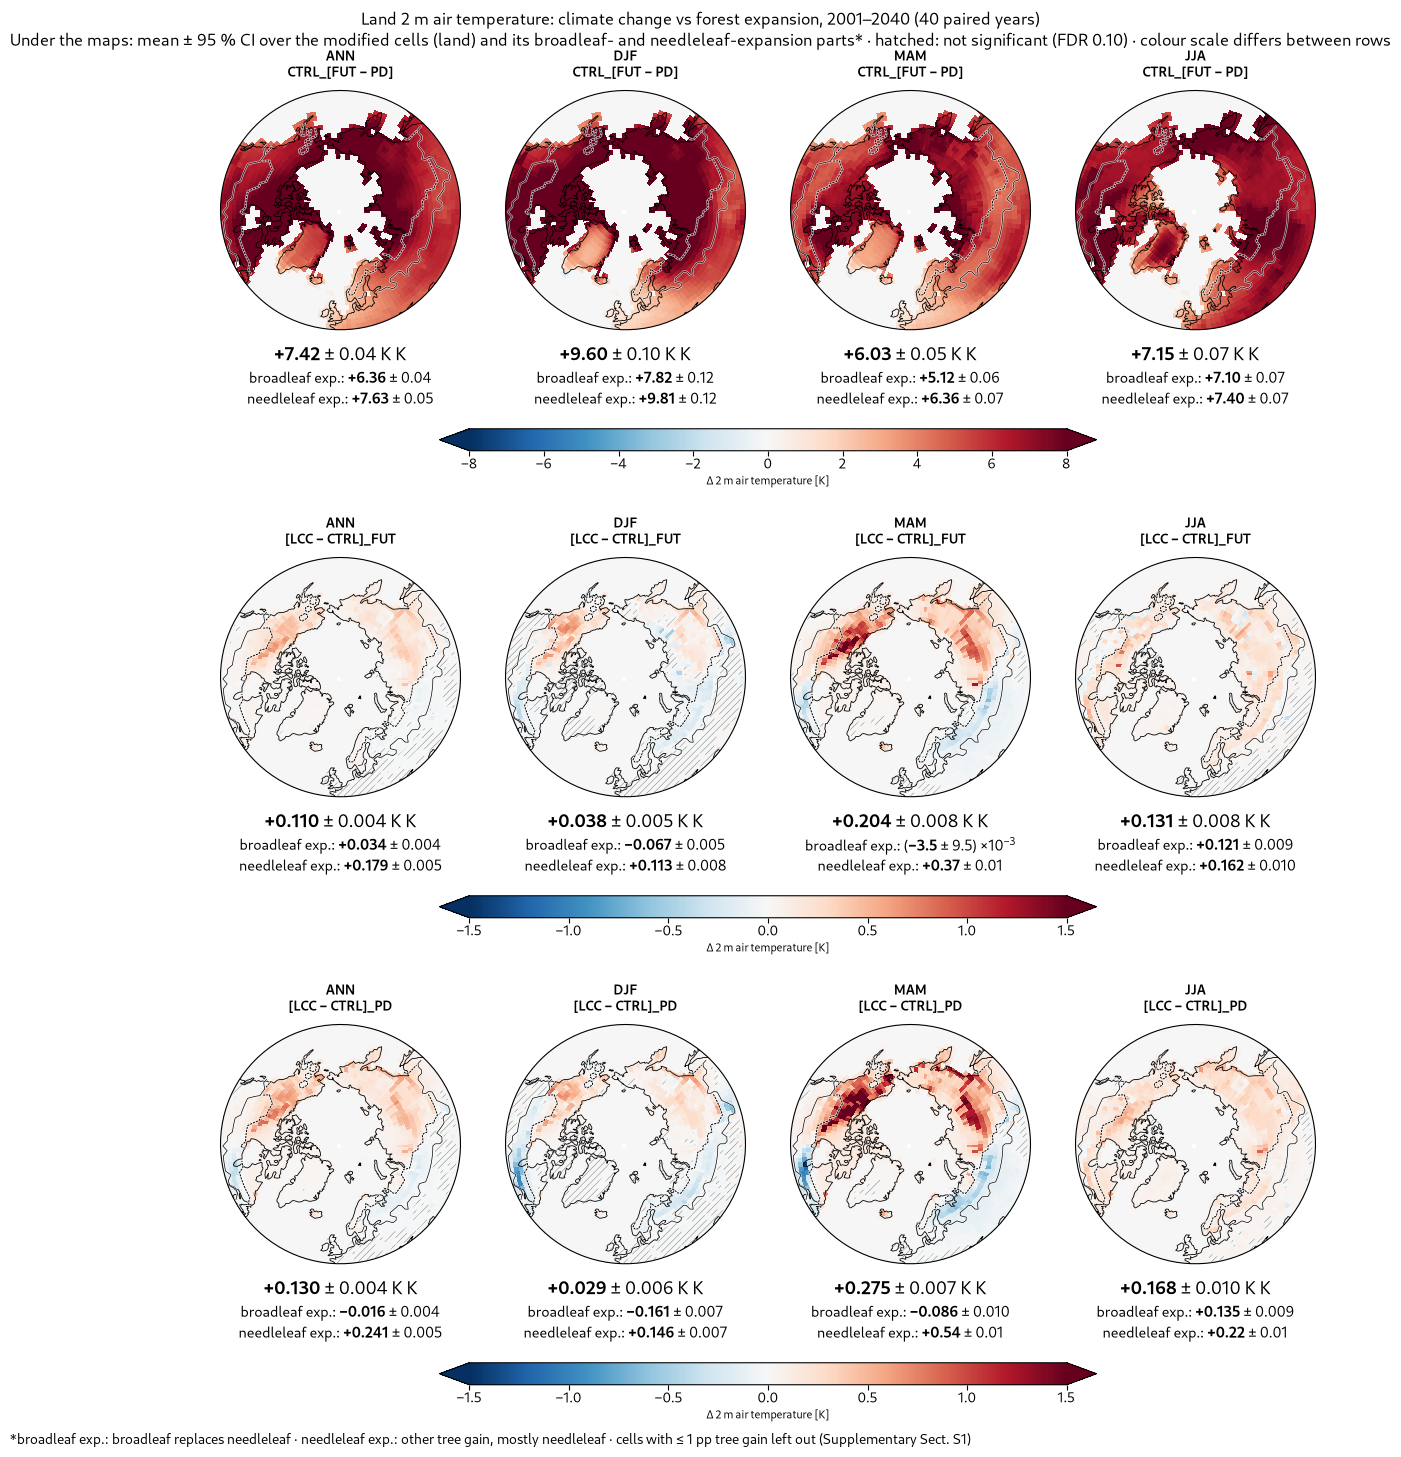

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/climate-vs-lcc-land-temperature/TSKIN_climate_vs_forest_maps_2001_2040.png


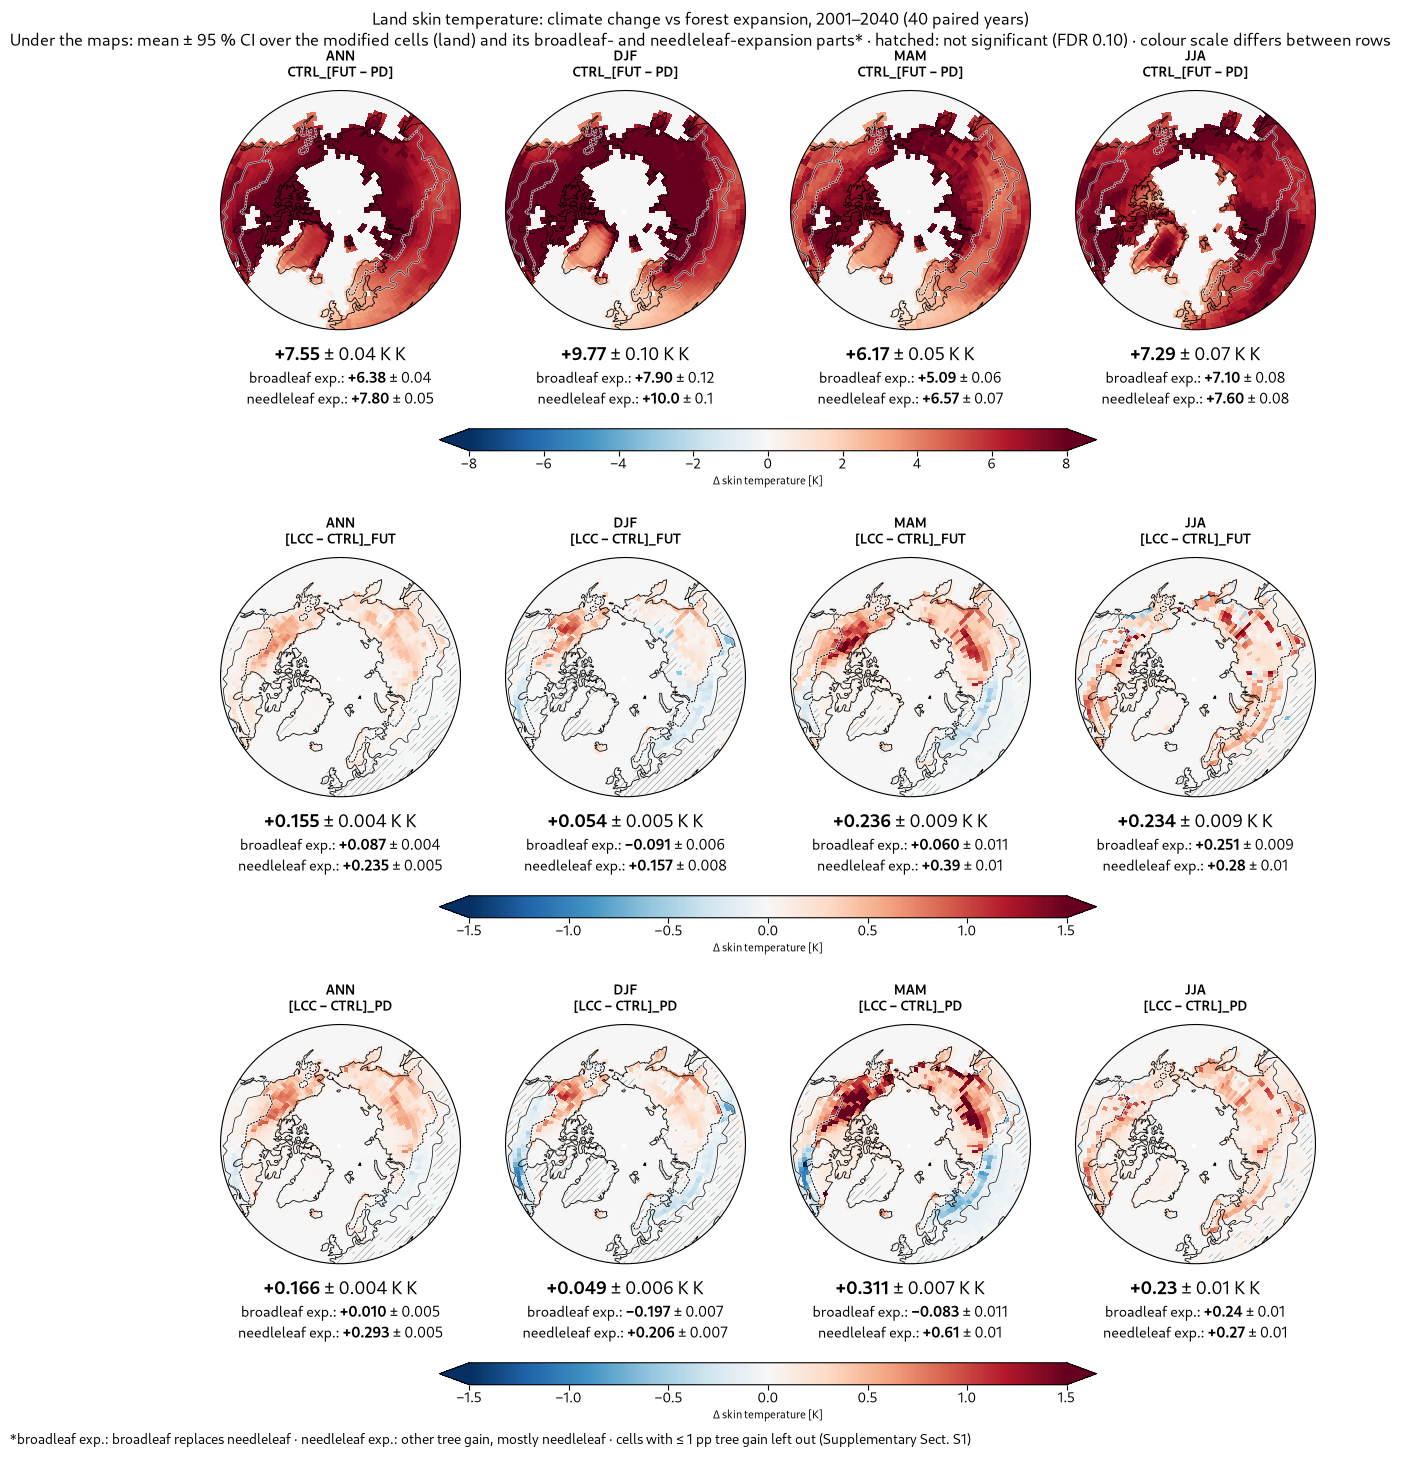

In [5]:
# Maps of TSA: row 1 climate, row 2 forest (FUT), row 3 forest (PD); columns = seasons; one colour scale per row
COLS = ["ANN", "DJF", "MAM", "JJA"]
ROWS = [(CLIMATE, 8.0), (FOREST, 1.5), ("[LCC − CTRL]_PD", 1.5)]
for v, vname in VARS.items():
    fig, axes = fm.map_grid(len(ROWS), len(COLS), left=1.6, titles_every_row=True)
    for i, (c, vmax) in enumerate(ROWS):
        for j, s in enumerate(COLS):
            d = D[c, v, s]
            p = cellwise_pvalue(d)
            north = d["lat"] >= LAT_MIN
            not_sig = (~fdr_mask(p, alpha=FDR_ALPHA, within=north)) & np.isfinite(p) & north
            mask = REGIONS["modified cells"]
            mean, half = interval(d.weighted(W.where(mask, 0.0)).mean(("lat", "lon")).values)
            reg = [f"{lab}: {fm._format_interval(*interval(d.weighted(W.where(rm & mask, 0.0)).mean(('lat', 'lon')).values))}"
                   for lab, rm in fm.vegetation_region_masks(d).items()]
            pm, _, _ = fm.plot_single_boreal_panel(
                axes[i, j], d.mean("year"), f"{s}\n{c}", units="K", vmax=vmax, extent_lat=LAT_MIN, add_cbar=False,
                sig=not_sig, sig_style="lines", mean_text=fm._format_interval(mean, half), region_text=reg)
        cb = fm._cbar_below(fig, axes[i, :], pm, f"Δ {vname} [K]", fm.CBAR_LABELSIZE_SHARED, shrink=0.6)
    fig.suptitle(f"Land {vname}: climate change vs forest expansion, {START_YEAR}–{END_YEAR} ({END_YEAR - START_YEAR + 1} paired years)\n"
                 "Under the maps: mean ± 95 % CI over the modified cells (land) and its broadleaf- and needleleaf-expansion parts* · "
                 "hatched: not significant (FDR 0.10) · colour scale differs between rows", fontsize=12)
    fm.add_region_footnote(fig)
    path = FIG / f"{v}_climate_vs_forest_maps_{START_YEAR}_{END_YEAR}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white"); print("Saved", path)
    plt.show(); plt.close(fig)

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/climate-vs-lcc-land-temperature/forest_over_climate_ratio_2001_2040.png


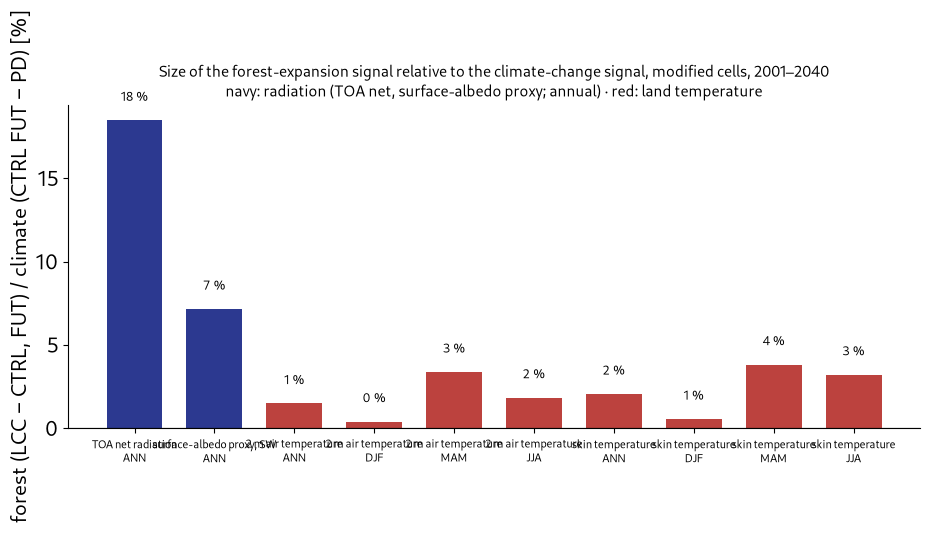

In [6]:
# Forest / climate ratio by measure and season (modified cells): how 'minor' depends on what is measured
SHORT = {"surface-albedo proxy": "surface-albedo SW proxy"}
sub = C[(C["region"] == "modified cells") & (C["season"] != "SON")].copy()
sub["name"] = sub["measure"].str.replace(r" \(.*$", "", regex=True).str.replace(r",.*$", "", regex=True)
sub["label"] = sub["name"].map(lambda s: SHORT.get(s, s)) + ", " + sub["season"]
sub = sub.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.6))
y = np.arange(len(sub))
ax.barh(y, sub["forest_over_climate_pct"], color=[RED if "temperature" in n else NAVY for n in sub["name"]], height=0.7)
for yi, v in zip(y, sub["forest_over_climate_pct"]):
    ax.text(v + 0.3, yi, f"{v:.1f} %", va="center", fontsize=9)
ax.set_yticks(y, sub["label"], fontsize=9)
ax.set_xlim(0, sub["forest_over_climate_pct"].max() * 1.15)
ax.set_xlabel(f"forest signal / climate signal [%]\nforest = {FOREST}, climate = {CLIMATE}")
ax.set_title(f"Forest-expansion signal relative to the climate-change signal\nmodified cells, {START_YEAR}–{END_YEAR} "
             "· navy: radiation (annual) · red: land temperature", fontsize=11)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
path = FIG / f"forest_over_climate_ratio_{START_YEAR}_{END_YEAR}.png"
fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white"); print("Saved", path)
plt.show(); plt.close(fig)

## Findings

(filled after the run, from the tables above)